# Post-processing: bias tuning and ensemble
Inputs: every `val_*.csv` / `test_*.csv` pair from attached notebook outputs, plus `train_clean.parquet` for val labels and groups.
All numbers are honest out-of-fold estimates: val is split into two halves by near-duplicate group, the stacker / bias is fitted on one half and evaluated on the other, then swapped.
- **raw**: argmax of the model's own scores
- **cal**: one-model logistic regression on its scores (calibration + class intercepts)
- **+bias**: per-class offsets on log-probs tuned for macro-F1
- **ensemble**: logistic regression stacker on all model scores

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

SEED = 42
LABELS = ['human', 'ai', 'fusion']
INPUT = Path('/kaggle/input')

train = pd.read_parquet(next(INPUT.rglob('train_clean.parquet')), columns=['id', 'lang', 'domain', 'label', 'fold', 'group'])
v = train[train.fold == 'val'].set_index('id')
del train
sample_sub = pd.read_csv(next(INPUT.rglob('sample_submission.csv')))
y = v.label.values

models = {}
for f in sorted(INPUT.rglob('val_*.csv')):
    t = f.with_name('test_' + f.name[4:])
    if t.exists():
        models[f.stem[4:]] = (pd.read_csv(f, index_col='id').loc[v.index], pd.read_csv(t, index_col='id').loc[sample_sub.id])
SINGLE = [m for m, (a, _) in models.items() if set(LABELS) <= set(a.columns)]
halves = list(StratifiedGroupKFold(2, shuffle=True, random_state=SEED).split(v, v.label, v.group))
pd.Series({m: a.shape[1] for m, (a, _) in models.items()}, name='n_cols')

scores_baseline             3
logits_xlmr_full            3
logits_xlmr_headtail        3
logits_mdeberta_headtail    3
probs_ppl                   3
probs_stylo                 3
scores_tfidf_stylo          3
Name: n_cols, dtype: int64

## Stacker and bias tuning

In [2]:
def macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

def tune_bias(logp, y_true, classes, grid=np.linspace(-2, 2, 41), rounds=3):
    b = np.zeros(len(classes))
    for _ in range(rounds):
        for k in range(1, len(classes)):
            def score(g):
                bb = b.copy()
                bb[k] = g
                return macro(y_true, classes[(logp + bb).argmax(1)])
            b[k] = max(grid, key=score)
    return b

def matrix(names, split):
    return pd.concat([models[m][split].add_prefix(f'{m}:') for m in names], axis=1).values

def fit(names, X, y_fit, bias):
    sc = StandardScaler().fit(X)
    lr = LogisticRegression(C=1, max_iter=2000).fit(sc.transform(X), y_fit)
    b = tune_bias(lr.predict_log_proba(sc.transform(X)), y_fit, lr.classes_) if bias else np.zeros(len(lr.classes_))
    return lambda Z: lr.classes_[(lr.predict_log_proba(sc.transform(Z)) + b).argmax(1)]

def oof(names, bias):
    X = matrix(names, 0)
    pred = np.empty(len(y), object)
    for a, b in halves:
        pred[b] = fit(names, X[a], y[a], bias)(X[b])
    return pred

def report(pred):
    f = f1_score(y, pred, labels=LABELS, average=None)
    return {**dict(zip(LABELS, f)), 'macro': f.mean()}

rows, oofs = {}, {}
for m in SINGLE:
    oofs[f'{m} | raw'] = models[m][0][LABELS].idxmax(axis=1).values
    oofs[f'{m} | cal'] = oof([m], False)
    oofs[f'{m} | cal+bias'] = oof([m], True)
ENSEMBLES = {'all': list(models)}
if len(models) > 2:
    ENSEMBLES.update({f'all - {m}': [n for n in models if n != m] for m in models})
for name, names in ENSEMBLES.items():
    oofs[f'{name} | ens'] = oof(names, False)
    oofs[f'{name} | ens+bias'] = oof(names, True)

results = pd.DataFrame({k: report(p) for k, p in oofs.items()}).T.sort_values('macro', ascending=False).round(4)
results

,human,ai,fusion,macro
all - logits_mdeberta_headtail | ens+bias,0.9260,0.9965,0.9380,0.9535
all - logits_xlmr_headtail | ens,0.9257,0.9966,0.9382,0.9535
all - logits_mdeberta_headtail | ens,0.9256,0.9965,0.9380,0.9534
all - scores_baseline | ens,0.9252,0.9966,0.9374,0.9531
all | ens+bias,0.9254,0.9966,0.9370,0.9530
all - probs_ppl | ens+bias,0.9254,0.9964,0.9371,0.9530
all - logits_xlmr_headtail | ens+bias,0.9249,0.9966,0.9373,0.9530
all | ens,0.9248,0.9966,0.9373,0.9529
all - scores_baseline | ens+bias,0.9256,0.9966,0.9364,0.9529
all - scores_tfidf_stylo | ens,0.9245,0.9963,0.9373,0.9527


## Stability of the best variants

In [3]:
top = results.index[:3].tolist()
pd.DataFrame({
    k: pd.concat({by: v.assign(pred=oofs[k]).groupby(by).apply(lambda d: f1_score(d.label, d.pred, average='macro'))
                  for by in ['lang', 'domain']})
    for k in top
}).round(4)

all - logits_mdeberta_headtail | ens+bias  \
lang   de-DE                                                      0.9531   
       en-EN                                                      0.9536   
domain arxiv_papers                                               0.8994   
       blog_authorship_corpus                                     0.8926   
       bundestag                                                  0.9534   
       cnn_news                                                   0.9794   
       euro_court_cases                                           0.9497   
       gutenberg                                                  0.8411   
       house_of_commons                                           0.9786   
       student_essays                                             0.9680   

                               all - logits_xlmr_headtail | ens  \
lang   de-DE                                             0.9537   
       en-EN                                             0.9534   
domain arxiv_papers                                      0.8981   
       blog_authorship_corpus                            0.8938   
       bundestag                                         0.9540   
       cnn_news                                          0.9787   
       euro_court_cases                                  0.9467   
       gutenberg                                         0.8423   
       house_of_commons                                  0.9794   
       student_essays                                    0.9680   

                               all - logits_mdeberta_headtail | ens  
lang   de-DE                                                 0.9537  
       en-EN                                                 0.9533  
domain arxiv_papers                                          0.8968  
       blog_authorship_corpus                                0.8919  
       bundestag                                             0.9539  
       cnn_news                                              0.9786  
       euro_court_cases                                      0.9496  
       gutenberg                                             0.8461  
       house_of_commons                                      0.9788  
       student_essays                                        0.9679

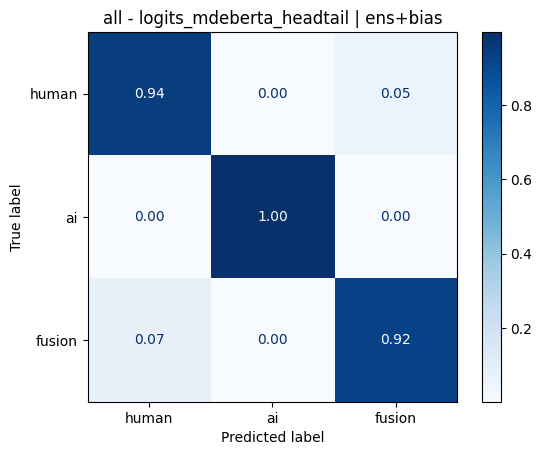

In [4]:
FIG = Path('figures')
FIG.mkdir(exist_ok=True)
ConfusionMatrixDisplay.from_predictions(y, oofs[top[0]], labels=LABELS, normalize='true', cmap='Blues', values_format='.2f')
plt.title(top[0])
plt.savefig(FIG / 'confusion_best.png', bbox_inches='tight')
plt.show()

## Final submissions
`FINAL` defaults to the best out-of-fold variant and `SAFE` to the best single model with bias; change them by name from `results` if needed. Stacker / bias are refitted on the full val fold.

In [5]:
FINAL = results.index[0]
SAFE = results[results.index.str.endswith('cal+bias')].index[0]

def names_of(key):
    name, kind = key.split(' | ')
    return (ENSEMBLES[name] if kind.startswith('ens') else [name]), kind.endswith('bias'), kind == 'raw'

for key in dict.fromkeys([FINAL, SAFE]):
    names, bias, raw = names_of(key)
    if raw:
        pred = models[names[0]][1][LABELS].idxmax(axis=1).values
    else:
        pred = fit(names, matrix(names, 0), y, bias)(matrix(names, 1))
    file = 'submission_' + key.replace(' | ', '__').replace(' ', '').replace('-', 'minus_') + '.csv'
    sample_sub.assign(label=pred).to_csv(file, index=False)
    print(file, results.loc[key, 'macro'], pd.Series(pred).value_counts(normalize=True).round(3).to_dict())

submission_allminus_logits_mdeberta_headtail__ens+bias.csv 0.9535 {'ai': 0.514, 'human': 0.259, 'fusion': 0.227}
submission_logits_xlmr_full__cal+bias.csv 0.9353 {'ai': 0.514, 'human': 0.253, 'fusion': 0.233}
